<a href="https://colab.research.google.com/github/raminass/Software-Project/blob/main/pandas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Author**: Rami Nasser (raminass@gmail.com), Yael Kupershmidt (kupershmidt@mail.tau.ac.il)


# Earlier

*   Numpy
*   Scipy
*   Matplotlib

# Today

*   Pandas









# Pandas

**Learning Objectives:**
  * Gain an introduction to the `DataFrame` and `Series` data structures of the *pandas* library
  * Access and manipulate data within a `DataFrame` and `Series`
  * Import CSV data into a *pandas* `DataFrame`


[*pandas*](https://pandas.pydata.org/) is a column-oriented data analysis API. It's a great tool for handling and analyzing input data, and many ML frameworks support *pandas* data structures as inputs.
Although a comprehensive introduction to the *pandas* API would span many pages, the core concepts are fairly straightforward, and we'll present them below. For a more complete reference, the [*pandas* docs site](https://pandas.pydata.org/docs/) contains extensive documentation and many tutorials.

## Setup

Install

The course Docker image already has pandas installed (see `requirements.txt`). On another machine, install it from a terminal with `pip install pandas`.

Import - External Package

In [1]:
import pandas as pd

def title(text, *values):
    # print the explanation in bold, then the values unchanged:
    # "\033[1m" turns bold on, "\033[0m" turns it off
    print("\033[1m" + text + "\033[0m", *values)

The primary data structures in *pandas* are implemented as two classes:

  * **`DataFrame`**, which you can imagine as a relational data table, with rows and named columns.
  * **`Series`**, which is a single column. A `DataFrame` contains one or more `Series` and a name for each `Series`.

The data frame is a commonly used abstraction for data manipulation. Similar implementations exist in [Spark](https://spark.apache.org/) and [R](https://www.r-project.org/about.html).

## Series

One way to create a `Series` is to construct a `Series` object. For example:

In [2]:
pd.Series(['San Francisco', 'San Jose', 'Sacramento'])

0    San Francisco
1         San Jose
2       Sacramento
dtype: str

## Creating Data

`DataFrame` objects can be created by passing a `dict` mapping `string` column names to their respective `Series`. If the `Series` don't match in length, missing values are filled with special [NA/NaN](https://pandas.pydata.org/docs/user_guide/missing_data.html) values. Example:

In [3]:
city_names = pd.Series(['San Francisco', 'San Jose', 'Sacramento'])
population = pd.Series([852469, 1015785, 485199])
cities = pd.DataFrame({'City name': city_names, 'Population': population})
title("DataFrame built from a dict of two Series:")
print(cities)
print()

# Missing values: population now has only 2 values for 3 cities
population = pd.Series([852469, 1015785])
cities = pd.DataFrame({'City name': city_names, 'Population': population})
title("Population has no value for the third city, so it is filled with NaN:")
print(cities)
title("NaN is a float, so the Population column becomes:", cities['Population'].dtype)

DataFrame built from a dict of two Series:
       City name  Population
0  San Francisco      852469
1       San Jose     1015785
2     Sacramento      485199

Population has no value for the third city, so it is filled with NaN:
       City name  Population
0  San Francisco    852469.0
1       San Jose   1015785.0
2     Sacramento         NaN
NaN is a float, so the Population column becomes: float64


A DataFrame is a table (like an Excel sheet). Each row is a record and each column holds one kind of value.

In the `city_names` / `Population` example above, the dictionary gave the **column** labels, but the **row** labels are just a count from 0 (0, 1, 2, ...). Sometimes this is OK, but often we want to choose these labels ourselves.

The list of row labels used in a DataFrame is known as an **Index**. We can set it with the `index` parameter of the constructor:

In [4]:
# Student list
students = pd.DataFrame({'Name': ['Ross', 'Monica','Chandler'],
              'Last Name': ['Geller', 'Geller','Bing'],
              'GPA': [98, 99, 90]},
               index=['id1', 'id2','id3'])
students

,Name,Last Name,GPA
id1,Ross,Geller,98
id2,Monica,Geller,99
id3,Chandler,Bing,90


### Changing a value

In pandas 3, **Copy-on-Write** is always on: every selection behaves like an independent copy.
So *chained* indexing such as `students['Name']['id1'] = ...` first creates a new Series (`students['Name']`), changes **that copy**, and leaves `students` unchanged. pandas warns with `ChainedAssignmentError`:

In [5]:
students['Name']['id1'] = 'Joey'   # does NOT change students
students

/tmp/ipykernel_2156642/4226053823.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment.
Such chained assignment never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

Try using '.loc[row_indexer, col_indexer] = value' instead, to perform the assignment in a single step.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html#chained-assignment
  students['Name']['id1'] = 'Joey'   # does NOT change students


,Name,Last Name,GPA
id1,Ross,Geller,98
id2,Monica,Geller,99
id3,Chandler,Bing,90


Use a single `.loc[row, column]` assignment instead:

In [6]:
title("students before the assignment:")
print(students)
print()

students.loc['id1', 'Name'] = 'Joey'
title("students after students.loc['id1', 'Name'] = 'Joey', the Name of id1 has changed:")
print(students)

students before the assignment:
         Name Last Name  GPA
id1      Ross    Geller   98
id2    Monica    Geller   99
id3  Chandler      Bing   90

students after students.loc['id1', 'Name'] = 'Joey', the Name of id1 has changed:
         Name Last Name  GPA
id1      Joey    Geller   98
id2    Monica    Geller   99
id3  Chandler      Bing   90


## Reading Data

Being able to create a DataFrame or Series by hand is handy. But, most of the time, we won't actually be creating our own data by hand. Instead, we'll be working with data that already exists.

Data can be stored in any of a number of different forms and formats. By far the most basic of these is the humble CSV file. When you open a CSV file you get something that looks like this:

```csv
A,B,C,
30,21,9,
35,34,1,
41,11,11
```



So a CSV file is a table of values separated by commas. Hence the name: "Comma-Separated Values", or CSV.

Let's now set aside our toy datasets and see what a real dataset looks like when we read it into a DataFrame. We'll use the pd.read_csv() function to read the data into a DataFrame.

Reading from web directly:

In [7]:
houses = pd.read_csv("https://download.mlcc.google.com/mledu-datasets/california_housing_train.csv")

We can use the shape attribute to check how large the resulting DataFrame is:



In [8]:
print(houses.shape)
houses

(17000, 9)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0
...,...,...,...,...,...,...,...,...,...
16995,-124.26,40.58,52.0,2217.0,394.0,907.0,369.0,2.3571,111400.0
16996,-124.27,40.69,36.0,2349.0,528.0,1194.0,465.0,2.5179,79000.0
16997,-124.30,41.84,17.0,2677.0,531.0,1244.0,456.0,3.0313,103600.0
16998,-124.30,41.80,19.0,2672.0,552.0,1298.0,478.0,1.9797,85800.0


We can examine the contents of the resultant DataFrame using the head()

command, which grabs the first five rows:

In [9]:
# arg the desired number of rows
houses.head(8)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0
5,-114.58,33.63,29.0,1387.0,236.0,671.0,239.0,3.3438,74000.0
6,-114.58,33.61,25.0,2907.0,680.0,1841.0,633.0,2.6768,82400.0
7,-114.59,34.83,41.0,812.0,168.0,375.0,158.0,1.7083,48500.0


Statistical overview of the dataset:

In [10]:
houses.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000
mean,-119.562108,35.625225,28.589353,2643.664412,539.410824,1429.573941,501.221941,3.883578,207300.912353
std,2.005166,2.137340,12.586937,2179.947071,421.499452,1147.852959,384.520841,1.908157,115983.764387
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.790000,33.930000,18.000000,1462.000000,297.000000,790.000000,282.000000,2.566375,119400.000000
50%,-118.490000,34.250000,29.000000,2127.000000,434.000000,1167.000000,409.000000,3.544600,180400.000000
75%,-118.000000,37.720000,37.000000,3151.250000,648.250000,1721.000000,605.250000,4.767000,265000.000000
max,-114.310000,41.950000,52.000000,37937.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [11]:
from IPython.display import display   # display() shows a DataFrame as a formatted table

title("Data type of each column:")
print(houses.dtypes)

title("\n5 random rows, random_state makes the choice repeatable:")
display(houses.sample(5, random_state=0))

title("Filtering: the first 5 houses whose median age is above 50 years:")
display(houses[houses['housing_median_age'] > 50].head(5))

Data type of each column:
longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
dtype: object

5 random rows, random_state makes the choice repeatable:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
3873,-117.95,33.84,18.0,3418.0,815.0,1961.0,773.0,3.6500,171400.0
3625,-117.92,34.08,36.0,1479.0,251.0,741.0,245.0,4.2986,189600.0
3028,-117.80,33.83,17.0,2971.0,350.0,1180.0,346.0,11.1228,500001.0
13814,-122.01,36.98,47.0,2403.0,517.0,1144.0,455.0,2.5954,229400.0
15398,-122.30,38.25,18.0,3548.0,880.0,1476.0,699.0,3.7188,163400.0


Filtering: the first 5 houses whose median age is above 50 years:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
325,-116.88,34.08,52.0,3419.0,777.0,710.0,265.0,3.9028,128600.0
1011,-117.10,32.76,52.0,2606.0,426.0,883.0,380.0,4.2813,270800.0
1074,-117.11,32.77,52.0,1506.0,233.0,478.0,240.0,4.3875,300000.0
1075,-117.11,32.77,52.0,1484.0,224.0,498.0,223.0,6.6053,331400.0
1103,-117.11,32.67,52.0,280.0,71.0,217.0,71.0,1.4844,83300.0


Reading from local storage:

In [12]:
from pathlib import Path

# A copy of the dataset is in the repository (data/tips.csv); fall back to the web copy if it is missing.
TIPS_PATH = Path('data/tips.csv')
TIPS_URL = 'https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv'
tips = pd.read_csv(TIPS_PATH if TIPS_PATH.exists() else TIPS_URL)

title("Shape of tips:", tips.shape)
tips.head()

Shape of tips: (244, 7)


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


## Accessing Data

Every column of a DataFrame is a **`Series`**. There are two ways to get one:

* attribute access: `houses.median_income`
* indexing: `houses['median_income']`

Both return the same Series. Prefer `[]`: it also works when the column name has a space, and when the name clashes with a DataFrame attribute. For example, in a table with a column called `size`, `df.size` is the number of cells in the table, while `df['size']` is the column.

A Series is like a dictionary from row label to value, so one more `[]` gives a single value. `.nunique()` counts the distinct values and `.unique()` lists them. Text columns have dtype `str` in pandas 3; older tutorials show `object` instead.

In [13]:
title("houses.median_income, first 3 rows:")
print(houses.median_income.head(3))
title("houses['median_income'] is the same Series:")
print(houses['median_income'].head(3))
title("type of houses['median_income']:", type(houses['median_income']))
print()

title("value of houses['median_house_value'] at row 200:", houses['median_house_value'][200])
title("number of distinct values of houses['housing_median_age']:", houses['housing_median_age'].nunique())
title("the first 10 distinct values:", houses['housing_median_age'].unique()[:10])

houses.median_income, first 3 rows:
0    1.4936
1    1.8200
2    1.6509
Name: median_income, dtype: float64
houses['median_income'] is the same Series:
0    1.4936
1    1.8200
2    1.6509
Name: median_income, dtype: float64
type of houses['median_income']: <class 'pandas.Series'>

value of houses['median_house_value'] at row 200: 73300.0
number of distinct values of houses['housing_median_age']: 52
the first 10 distinct values: [15. 19. 17. 14. 20. 29. 25. 41. 34. 46.]


## Indexing

`houses.median_income` and `houses['median_income']` select **columns**. To select **rows**, or rows and columns together, pandas has two accessors. Both take `[rows, columns]`, rows first:

| Accessor | Selects by | Slice end `a:b` | Example |
|---|---|---|---|
| `iloc` | **position**: 0, 1, 2, ... like a Python list | excluded | `houses.iloc[103:107, 0]` gives positions 103 to 106 |
| `loc` | **label**: the values of the index | **included** | `houses.loc[103:107, 'median_income']` gives labels 103 to 107 |

More info in the documentation: [indexing and selection](https://pandas.pydata.org/docs/user_guide/indexing.html).

### 1. `[]` selects columns, not rows

Plain `[]` on a DataFrame always looks up **column labels**, so `houses[-2]` does not give the second last row: it raises a `KeyError`, because there is no column named `-2`. The cell catches the error with `try` / `except` and prints it.

In [14]:
try:
    houses[-2]
except KeyError as err:
    title("houses[-2] fails, there is no column named -2:", f"{type(err).__name__}: {err}")

houses[-2] fails, there is no column named -2: KeyError: -2


### 2. `iloc`: select by position

In [15]:
title("houses.iloc[-2], the second last row:")
print(houses.iloc[-2])
print()
title("houses.iloc[:, 0], the first column, first 3 rows:")
print(houses.iloc[:, 0].head(3))
print()
title("houses.iloc[103:107, 0], positions 103 to 106, the end is excluded:")
print(houses.iloc[103:107, 0])

houses.iloc[-2], the second last row:
longitude              -124.3000
latitude                 41.8000
housing_median_age       19.0000
total_rooms            2672.0000
total_bedrooms          552.0000
population             1298.0000
households              478.0000
median_income             1.9797
median_house_value    85800.0000
Name: 16998, dtype: float64

houses.iloc[:, 0], the first column, first 3 rows:
0   -114.31
1   -114.47
2   -114.56
Name: longitude, dtype: float64

houses.iloc[103:107, 0], positions 103 to 106, the end is excluded:
103   -115.60
104   -115.62
105   -115.62
106   -115.64
Name: longitude, dtype: float64


### 3. `loc`: select by label

Compare with the last `iloc` example: the same numbers `103:107`, but `loc` includes the end.

In [16]:
title("houses.loc[103:107, 'median_income'], labels 103 to 107, the end is included:")
print(houses.loc[103:107, 'median_income'])

houses.loc[103:107, 'median_income'], labels 103 to 107, the end is included:
103    4.1293
104    2.2969
105    2.0463
106    3.1667
107    2.1792
Name: median_income, dtype: float64


### 4. `set_index`: use a column as the row labels

After `set_index('housing_median_age')`, the row labels are house ages, so `loc` can select all rows with one age.

In [17]:
df = houses.set_index('housing_median_age')
title("df = houses.set_index('housing_median_age'), first 3 rows:")
display(df.head(3))
print()
title("df.loc[52, 'median_house_value'], values of the houses that are 52 years old, first 3:")
print(df.loc[52, 'median_house_value'].head(3))

df = houses.set_index('housing_median_age'), first 3 rows:


,longitude,latitude,total_rooms,total_bedrooms,population,households,median_income,median_house_value
housing_median_age,,,,,,,,
15.0,-114.31,34.19,5612.0,1283.0,1015.0,472.0,1.4936,66900.0
19.0,-114.47,34.40,7650.0,1901.0,1129.0,463.0,1.8200,80100.0
17.0,-114.56,33.69,720.0,174.0,333.0,117.0,1.6509,85700.0



df.loc[52, 'median_house_value'], values of the houses that are 52 years old, first 3:
housing_median_age
52.0    128600.0
52.0    270800.0
52.0    300000.0
Name: median_house_value, dtype: float64


## Manipulating Data

Arithmetic on a `Series` is applied to every row at once, just like on a NumPy array. You can combine a column with a number, combine two columns row by row, apply NumPy functions to a column, and store any result as a new column with `houses['name'] = ...`.

In [18]:
import numpy as np

# A column combined with a number: the house value in thousands of dollars
houses['value_k'] = houses['median_house_value'] / 1000

# Two columns combined row by row: rooms per household in each district
houses['rooms_per_household'] = houses['total_rooms'] / houses['households']

# A NumPy function applied to a whole column
houses['log_income'] = np.log(houses['median_income'])

# A condition turned into a text column: north or south of latitude 36
houses['region'] = np.where(houses['latitude'] >= 36, 'north', 'south')

title("houses with the new columns, first 3 rows:")
display(houses[['median_house_value', 'value_k', 'total_rooms', 'households',
                'rooms_per_household', 'median_income', 'log_income', 'latitude', 'region']].head(3))

houses with the new columns, first 3 rows:


,median_house_value,value_k,total_rooms,households,rooms_per_household,median_income,log_income,latitude,region
0,66900.0,66.9,5612.0,472.0,11.889831,1.4936,0.401189,34.19,south
1,80100.0,80.1,7650.0,463.0,16.522678,1.8200,0.598837,34.40,south
2,85700.0,85.7,720.0,117.0,6.153846,1.6509,0.501321,33.69,south


Summarizing data: `value_counts()` counts how often each value appears.

In [19]:
title("number of districts in each region:")
print(houses['region'].value_counts())
print()
title("the 5 most common house ages:")
print(houses['housing_median_age'].value_counts().head(5))

number of districts in each region:
region
south    9755
north    7245
Name: count, dtype: int64

the 5 most common house ages:
housing_median_age
52.0    1052
36.0     715
35.0     692
16.0     635
17.0     576
Name: count, dtype: int64


## Filtering

So far we've selected data by its position or label. To do interesting things with the data, however, we often need to ask questions based on conditions, as in a database query.

* A condition such as `houses['region'] == 'north'` gives a Boolean Series, one `True`/`False` per row; `houses[condition]` keeps the rows where it is `True`.
* To combine conditions, use `&` for "and" and `|` for "or", and put each condition in parentheses.
* `isin([...])` checks for several values at once, instead of chaining many `|`.

In [20]:
title("districts in the north, first 5:")
display(houses[houses['region'] == 'north'].head())

title("districts in the north with a median house value above 400,000, first 5:")
display(houses[(houses['region'] == 'north') & (houses['median_house_value'] > 400000)].head())

title("districts whose house age is 10 or 20 and value above 400,000, first 5:")
display(houses[(houses['housing_median_age'].isin([10, 20])) & (houses['median_house_value'] > 400000)].head())

districts in the north, first 5:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,value_k,rooms_per_household,log_income,region
157,-116.22,36.00,14.0,1372.0,386.0,436.0,213.0,1.1471,32900.0,32.900,6.441315,0.137237,north
568,-117.02,36.40,19.0,619.0,239.0,490.0,164.0,2.1000,14999.0,14.999,3.774390,0.741937,north
2709,-117.69,36.13,25.0,1709.0,439.0,632.0,292.0,1.7868,45500.0,45.500,5.852740,0.580426,north
4523,-118.05,36.64,34.0,2090.0,478.0,896.0,426.0,2.0357,74200.0,74.200,4.906103,0.710840,north
5596,-118.18,37.35,16.0,3806.0,794.0,1501.0,714.0,2.1212,108300.0,108.300,5.330532,0.751982,north


districts in the north with a median house value above 400,000, first 5:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,value_k,rooms_per_household,log_income,region
10301,-120.06,39.01,19.0,2967.0,528.0,112.0,48.0,4.0714,437500.0,437.500,61.812500,1.403987,north
10339,-120.10,38.91,33.0,1561.0,282.0,30.0,11.0,1.8750,500001.0,500.001,141.909091,0.628609,north
11123,-121.01,37.74,14.0,2368.0,297.0,796.0,301.0,8.7783,435000.0,435.000,7.867110,2.172283,north
11968,-121.38,38.60,36.0,1249.0,159.0,362.0,143.0,6.8469,446400.0,446.400,8.734266,1.923796,north
11996,-121.39,38.58,41.0,2577.0,365.0,913.0,339.0,6.3406,448300.0,448.300,7.601770,1.846973,north


districts whose house age is 10 or 20 and value above 400,000, first 5:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,value_k,rooms_per_household,log_income,region
1224,-117.13,32.63,10.0,7374.0,1157.0,1900.0,794.0,8.7991,478500.0,478.500,9.287154,2.174649,south
1528,-117.21,33.03,20.0,3370.0,433.0,1020.0,408.0,11.0911,500001.0,500.001,8.259804,2.406143,south
1745,-117.25,32.99,10.0,4926.0,749.0,1478.0,634.0,7.4720,439900.0,439.900,7.769716,2.011163,south
2542,-117.64,33.63,10.0,4814.0,643.0,1808.0,588.0,8.7980,436600.0,436.600,8.187075,2.174524,south
2587,-117.65,33.48,10.0,3484.0,582.0,1469.0,556.0,5.4188,402200.0,402.200,6.266187,1.689874,south


Data cleaning: in modern apps and research we often have missing data, for technical or business reasons; in clinical research, for example, a patient might not answer some questions. It is up to the researcher to decide how to handle missing data (this is a topic in ML).
The naive way is to drop the rows with missing values. The houses data has no missing values, so we use the `cities` table from the beginning of the lesson, where Sacramento has no population:

In [21]:
title("missing values in houses:", houses.isna().sum().sum())
print()
title("cities:")
print(cities)
print()
# dropna removes every row that has a missing value; subset=[...] checks only some columns
title("cities.dropna():")
print(cities.dropna())

missing values in houses: 0

cities:
       City name  Population
0  San Francisco    852469.0
1       San Jose   1015785.0
2     Sacramento         NaN

cities.dropna():
       City name  Population
0  San Francisco    852469.0
1       San Jose   1015785.0


## Grouping and Sorting

Besides built-in summaries such as `count()`, `sum()`, `mean()` and `nunique()` on a whole column, we can **group** the rows: `groupby('col')` splits the rows by the values of a column, applies a calculation to each group, and combines the results into one Series, one value per group. Grouping by a list of columns gives one value per combination.

`sort_values(by=..., ascending=False)` orders the rows by a column, largest first.

In [22]:
title("average house value in each region:")
print(houses.groupby('region')['median_house_value'].mean())
print()

title("average rooms per household by house age, the 5 highest:")
avg_rooms = houses.groupby('housing_median_age')['rooms_per_household'].mean()
print(avg_rooms.sort_values(ascending=False).head())

average house value in each region:
region
north    193973.456591
south    217199.161148
Name: median_house_value, dtype: float64

average rooms per household by house age, the 5 highest:
housing_median_age
1.0     13.909515
2.0      7.277255
3.0      6.911618
8.0      6.344858
11.0     6.318331
Name: rooms_per_household, dtype: float64


In [23]:
title("the most expensive districts, sorted by house value:")
display(houses.sort_values(by='median_house_value', ascending=False).head())

the most expensive districts, sorted by house value:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,value_k,rooms_per_household,log_income,region
2698,-117.68,33.57,2.0,10008.0,1453.0,3550.0,1139.0,10.1122,500001.0,500.001,8.786655,2.313743,south
7156,-118.32,33.77,37.0,627.0,95.0,259.0,106.0,6.8870,500001.0,500.001,5.915094,1.929636,south
7157,-118.32,33.75,37.0,1080.0,135.0,366.0,142.0,11.6677,500001.0,500.001,7.605634,2.456824,south
7158,-118.32,33.75,33.0,2996.0,398.0,1048.0,387.0,9.2670,500001.0,500.001,7.741602,2.226460,south
7159,-118.32,33.74,24.0,6097.0,794.0,2248.0,806.0,10.1357,500001.0,500.001,7.564516,2.316064,south


In [24]:
title("average house value for each region and house age, first 10:")
print(houses.groupby(['region', 'housing_median_age'])['median_house_value'].mean().head(10))

average house value for each region and house age, first 10:


region  housing_median_age
north   1.0                   190250.000000
        2.0                   221238.888889
        3.0                   191287.500000
        4.0                   209208.574468
        5.0                   206181.983607
        6.0                   190444.186047
        7.0                   177407.606061
        8.0                   183615.189873
        9.0                   172850.698630
        10.0                  158155.359223
Name: median_house_value, dtype: float64


## Combining Data

Two small hand-written tables, so the output is the same every time. They share the key column `id`, but not every id is in both tables:

* ids 1005 and 1006 are customers with no row in `df_info`;
* id 1007 has a row in `df_info` but is not a customer.



In [25]:
from IPython.display import HTML

def side_by_side(*tables):
    # tables are (title, DataFrame) pairs; show them in one row as HTML
    html = "".join(f'<div style="margin-right:2em"><b>{title}</b>{df.to_html(index=False)}</div>'
                   for title, df in tables)
    display(HTML(f'<div style="display:flex; align-items:flex-start">{html}</div>'))

df_customer = pd.DataFrame({
    'id':   [1001, 1002, 1003, 1004, 1005, 1006],
    'name': ['Dana Cohen', 'Yossi Levi', 'Maya Katz', 'Omer Ben-David', 'Noa Friedman', 'Amit Shapiro'],
})
df_info = pd.DataFrame({
    'id':      [1001, 1002, 1003, 1004, 1007],
    'age':     [34, 27, 45, 52, 29],
    'city':    ['Tel Aviv', 'Haifa', 'Jerusalem', 'Beer Sheva', 'Eilat'],
    'company': ['Alpha Ltd', 'Beta Inc', 'Gamma Co', 'Delta Labs', 'Epsilon Co'],
})

side_by_side(("df_customer", df_customer), ("df_info", df_info))

### Join/Merge

`pd.merge(left, right, on='id', how=...)` puts the columns of two tables side by side, matching rows by the key `id`. `how` decides which ids are kept:

| `how=` | Keeps | Rows here |
|---|---|---|
| `'inner'` | only ids in **both** tables | 4 |
| `'left'` | every id of the **left** table; missing right values become `NaN` | 6 |
| `'outer'` | every id of **either** table | 7 |

`indicator=True` adds a column `_merge` that says where each row came from: `both`, `left_only` or `right_only`.

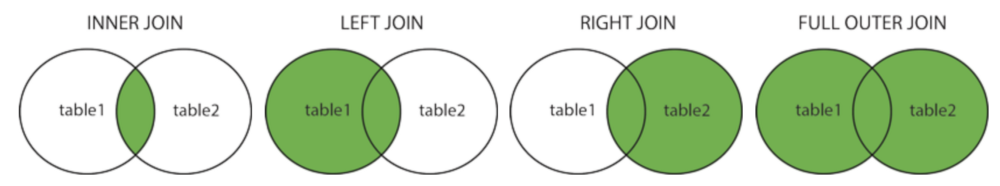

In [26]:
tables = []
for how in ['inner', 'left', 'outer']:
    result = pd.merge(df_customer, df_info, on='id', how=how, indicator=True)
    tables.append((f"how='{how}', {len(result)} rows", result))
side_by_side(*tables)

id,name,age,city,company,_merge
1001,Dana Cohen,34,Tel Aviv,Alpha Ltd,both
1002,Yossi Levi,27,Haifa,Beta Inc,both
1003,Maya Katz,45,Jerusalem,Gamma Co,both
1004,Omer Ben-David,52,Beer Sheva,Delta Labs,both
id,name,age,city,company,_merge
1001,Dana Cohen,34.0,Tel Aviv,Alpha Ltd,both
1002,Yossi Levi,27.0,Haifa,Beta Inc,both
1003,Maya Katz,45.0,Jerusalem,Gamma Co,both
1004,Omer Ben-David,52.0,Beer Sheva,Delta Labs,both
1005,Noa Friedman,NaN,NaN,NaN,left_only


In the `left` result, ids 1005 and 1006 have no match in `df_info`, so their `age`, `city` and `company` are missing (`NaN`).
Notice that `age` is shown as `34.0`, a `float64` column: `NaN` is a floating-point value, so an integer column with missing values is stored as float.
If you need integers with missing values, use the nullable `Int64` dtype, for example `df_info.astype({'age': 'Int64'})`.

In [27]:
title("type of age in df_info:", df_info['age'].dtype)

left = pd.merge(df_customer, df_info, how='left', on='id')
title("type of age after the left merge, NaN forces float:", left['age'].dtype)
print()

# The nullable Int64 dtype, with a capital I, can hold missing values
fixed = pd.merge(df_customer, df_info.astype({'age': 'Int64'}), how='left', on='id')
title("type of age with the nullable Int64 dtype:", fixed['age'].dtype)
side_by_side(("age after the left merge", left[['id', 'age']]),
             ("age with Int64", fixed[['id', 'age']]))

type of age in df_info: int64
type of age after the left merge, NaN forces float: float64

type of age with the nullable Int64 dtype: Int64


id,age
1001,34.0
1002,27.0
1003,45.0
1004,52.0
1005,NaN
1006,NaN
id,age
1001,34
1002,27
1003,45


### Union

Assume we have another store with its own customers, in a table with the **same columns**. Combining the **rows** of both tables into one table is called *union* in SQL and `pd.concat` in pandas.

`pd.concat` keeps the original row labels, so both tables bring labels 0, 1, 2, 3 and the labels repeat. `ignore_index=True` numbers the result again from 0.

In [28]:
df_customer_1 = pd.DataFrame({
    'id':   [2001, 2002, 2003, 2004],
    'name': ['Lior Mizrahi', 'Tamar Peretz', 'Eitan Biton', 'Shira Azulay'],
})

union = pd.concat([df_customer, df_customer_1], ignore_index=True)
side_by_side(("df_customer, 6 rows", df_customer),
             ("df_customer_1, 4 rows", df_customer_1),
             (f"pd.concat(...), {len(union)} rows", union))

title("without ignore_index=True the row labels repeat, so .loc[2] finds two rows:")
print(pd.concat([df_customer, df_customer_1]).loc[2])

id,name
1001,Dana Cohen
1002,Yossi Levi
1003,Maya Katz
1004,Omer Ben-David
1005,Noa Friedman
1006,Amit Shapiro
id,name
2001,Lior Mizrahi
2002,Tamar Peretz
2003,Eitan Biton


without ignore_index=True the row labels repeat, so .loc[2] finds two rows:
     id         name
2  1003    Maya Katz
2  2003  Eitan Biton


## Apply

So far every operation was built into pandas: arithmetic, comparisons, `mean()`, ... When you need your **own** logic, `apply` runs a Python function for you:

| Call | The function receives | Result |
|---|---|---|
| `series.apply(func)` | one value at a time | a new Series, one result per value |
| `df.apply(func, axis=1)` | one **row** at a time, as a Series | a new Series, one result per row |

`apply` is a Python loop in disguise, so it is slower than built-in, vectorized operations. 

### The dataset: student performance

The [Student Performance dataset](https://archive.ics.uci.edu/dataset/320/student+performance) (UCI Machine Learning Repository, CC BY 4.0) describes **395 students** of a mathematics course at two Portuguese secondary schools. Each row is one student, with 33 columns. The ones we use:

| Column | Meaning |
|---|---|
| `school` | `GP` (Gabriel Pereira) or `MS` (Mousinho da Silveira) |
| `sex`, `age` | `F` / `M`; age from 15 to 22 |
| `Medu`, `Fedu` | mother's / father's education, 0 (none) to 4 (higher education) |
| `Mjob`, `Fjob` | mother's / father's job: `teacher`, `health`, `services`, `at_home` or `other` |
| `guardian` | `mother`, `father` or `other` |
| `G1`, `G2`, `G3` | grade in the first period, second period and final grade, from 0 to 20 |


In [29]:
# A copy of the dataset is in the repository; fall back to the web copy if it is missing.
STUDENTS_PATH = Path('data/student-mat.csv')
STUDENTS_URL = 'https://raw.githubusercontent.com/guipsamora/pandas_exercises/master/04_Apply/Students_Alcohol_Consumption/student-mat.csv'
df = pd.read_csv(STUDENTS_PATH if STUDENTS_PATH.exists() else STUDENTS_URL)

title("shape of df, one row per student:", df.shape)
display(df.head(3))

shape of df, one row per student: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10


### 1. `Series.apply` with a `lambda`: capitalize the job names



In [30]:
capitalizer = lambda x: x.capitalize()

title("Mjob values before:", df['Mjob'].unique().tolist())
df['Mjob'] = df['Mjob'].apply(capitalizer)
title("Mjob values after apply(capitalizer):", df['Mjob'].unique().tolist())

df['Fjob'] = df['Fjob'].str.capitalize()   # the vectorized way
title("Fjob values after .str.capitalize():", df['Fjob'].unique().tolist())

Mjob values before: ['at_home', 'health', 'other', 'services', 'teacher']
Mjob values after apply(capitalizer): ['At_home', 'Health', 'Other', 'Services', 'Teacher']
Fjob values after .str.capitalize(): ['Teacher', 'Other', 'Services', 'Health', 'At_home']


### 2. `Series.apply` with a `def` function: a new True/False  legal_drinker column

In [31]:
def majority(age):
    if age > 17:
        return True
    else:
        return False

df['legal_drinker'] = df['age'].apply(majority)
display(df[['age', 'legal_drinker']].head())

title("number of students in each group:")
print(df['legal_drinker'].value_counts())
title("same column with the vectorized comparison age > 17:",
      (df['age'] > 17).equals(df['legal_drinker']))

,age,legal_drinker
0,18,True
1,17,False
2,15,False
3,15,False
4,16,False


number of students in each group:
legal_drinker
False    284
True     111
Name: count, dtype: int64
same column with the vectorized comparison age > 17: True


### 3. `DataFrame.apply(..., axis=1)`: average of the three grades of each student


In [32]:
def average_grade(row):
    return (row['G1'] + row['G2'] + row['G3']) / 3

df['avg_grade'] = df.apply(average_grade, axis=1)
display(df[['G1', 'G2', 'G3', 'avg_grade']].head())

with_lambda = df.apply(lambda row: (row['G1'] + row['G2'] + row['G3']) / 3, axis=1)
vectorized = df[['G1', 'G2', 'G3']].mean(axis=1)

,G1,G2,G3,avg_grade
0,5,6,6,5.666667
1,5,5,6,5.333333
2,7,8,10,8.333333
3,15,14,15,14.666667
4,6,10,10,8.666667


# Matplotlib

In [33]:
import matplotlib.pyplot as plt

By running this special iPython command, we will be displaying plots inline:

In [34]:
%matplotlib inline

## Plotting with subplots

`plt.subplot(rows, cols, k)` splits one figure into a grid of plots and makes the `k`-th plot the active one; the following `plt.` calls draw on it. The figure below has 3 rows and 1 column, and shows the houses data in three ways:

1. **House value by location.** Each dot is one district, placed at its longitude (x) and latitude (y), so the dots draw the shape of California. The colour is the median house value: the most expensive districts (yellow) lie along the coast, around San Francisco and Los Angeles.
2. **Distribution of house values.** A histogram: the values are split into 50 bins, and each bar counts the districts in one bin. Half of the districts are between about 120,000 and 265,000. The tall bar at the right end is an artefact of the data: values above 500,000 were capped at 500,001.
3. **Income vs house value.** Each dot is one district, with its median income (in tens of thousands of dollars) on x and its median house value on y. Districts with higher income have more expensive houses; the horizontal line at the top is the same 500,000 cap.

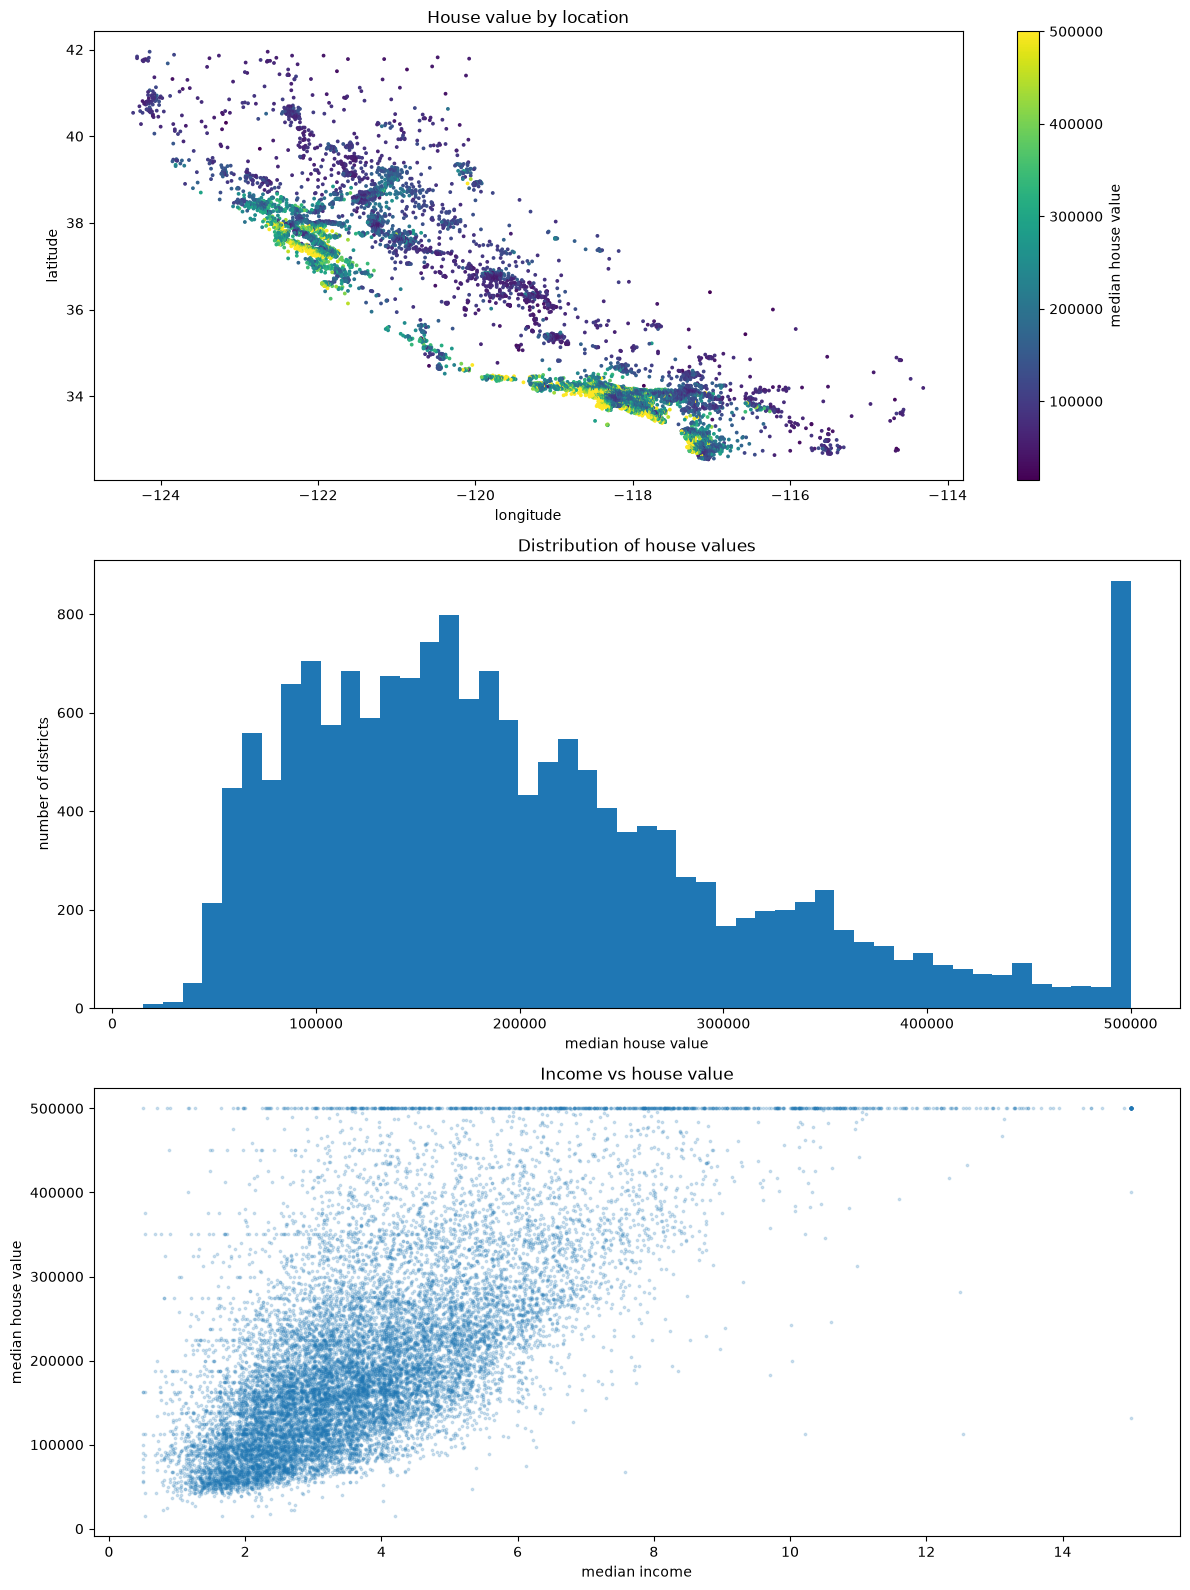

In [35]:
# A grid of 3 rows and 1 column; plt.subplot(3, 1, k) makes the k-th plot active.
plt.figure(figsize=(12,16))

# First plot: the districts on a map, coloured by house value
plt.subplot(3, 1, 1)
plt.scatter(houses['longitude'], houses['latitude'], c=houses['median_house_value'], s=3)
plt.colorbar(label='median house value')
plt.title('House value by location')
plt.xlabel('longitude')
plt.ylabel('latitude')

# Second plot: how house values are distributed
plt.subplot(3, 1, 2)
plt.hist(houses['median_house_value'], bins=50)
plt.title('Distribution of house values')
plt.xlabel('median house value')
plt.ylabel('number of districts')

# Third plot: income against house value
plt.subplot(3, 1, 3)
plt.scatter(houses['median_income'], houses['median_house_value'], s=3, alpha=0.2)
plt.title('Income vs house value')
plt.xlabel('median income')
plt.ylabel('median house value')

plt.tight_layout()   # stop titles and labels from overlapping
plt.show()

You can read much more about the `subplot` function in the [documentation](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplot.html).